# Notebook 01 — Which countries send care workers to Germany?

**Project:** Searching for Work in Germany: Google Trends Signals of Labour Migration Interest and Policy Effects (focus: migrant care workers)
**Author:** Tayaphon Rodsai · MSc Data Science for Society and Business, Constructor University
**Supervisor:** Prof. Erkan Gunes
**Course:** MDSSB-CAP-01 Capstone Project (Fall 2026)

---

### The question

Google Trends can only be studied for a limited number of countries. Before collecting any search data, we need to know: **which origin countries really send care workers to Germany?** The choice should come from **evidence, not from opinion**.

### Short answer

Combining three official sources, **9 countries** are selected: **India, Türkiye, Viet Nam, Morocco, Tunisia, the Philippines, Indonesia, Bosnia and Herzegovina and Cameroon.**

The way there had three surprises:
1. Work permits alone **hide** important care countries such as Viet Nam.
2. Many care workers come through **vocational training (Ausbildung)**, which Eurostat counts as "other education", not as work.
3. The data points to **Morocco and Cameroon**, which were not in the original plan, while **Brazil** drops out.

## 1. Where this step fits in the project

| # | Notebook | Research question |
|---|---|---|
| **01** | **Country selection** (this notebook) | — |
| 02 | Keyword discovery | — |
| 03 | Collect Google Trends data | — |
| 04 | Calibration with `gtab` | **RQ1 – Fix:** How can Google Trends be made comparable across countries and time? |
| 05 | Searches vs. permits | **RQ2 – Check:** Does search interest follow real first permits? |
| 06 | Policy comparison | **RQ3 – Compare:** Did interest grow after the 2023–2024 reforms, compared with Canada, the UK and Australia? |

## 2. Setup

All imports, folder paths and one helper function in one place.

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.float_format", "{:,.0f}".format)  # show 11069.0 as 11,069

# Folder paths (this notebook lives in /notebooks)
RAW = Path("../data/raw")
PROCESSED = Path("../data/processed")
FIGURES = Path("../reports/figures")
for folder in (RAW, PROCESSED, FIGURES):
    folder.mkdir(parents=True, exist_ok=True)

# Eurostat rows that are groups, not countries
GROUPS = ["Total", "Stateless", "Unknown", "Recognised non-citizens"]


def load_eurostat(url, file):
    """Load a saved snapshot if it exists; otherwise download from Eurostat and save it."""
    if file.exists():
        print("Loaded saved snapshot:", file.name)
        return pd.read_csv(file)
    data = pd.read_csv(url)
    data.to_csv(file, index=False)
    print("Downloaded from Eurostat and saved:", file.name)
    return data


def clean_permits(raw_data):
    """Keep 3 columns, remove group rows, reshape to one row per country and one column per year."""
    data = raw_data[["citizen", "TIME_PERIOD", "OBS_VALUE"]].rename(
        columns={"citizen": "country", "TIME_PERIOD": "year", "OBS_VALUE": "permits"}
    )
    data = data[~data["country"].isin(GROUPS)]
    return data.pivot_table(index="country", columns="year", values="permits")

---
## 3. Step 1 — Starting point: work permits

**Eurostat – First permits by reason, length of validity and citizenship** (`migr_resfirst`)

| Filter | Value | Why |
|---|---|---|
| Reporting country (`geo`) | Germany | Permits issued **by** Germany |
| Reason | Employment reasons (`EMP`) | First idea: care workers come to work |
| Duration | Total | All permits, short and long |
| Unit | Person | Number of people |
| Years | 2023, 2024, 2025 | Three years, so one unusual year does not decide the selection |
| Citizenship | All non-EU countries | EU citizens do not need a permit (shown as `:` / flag `m`) |

The first download is saved in `data/raw/`, so the results can be repeated even if Eurostat updates its numbers later.

In [2]:
URL = "https://ec.europa.eu/eurostat/api/dissemination/sdmx/3.0/data/dataflow/ESTAT/migr_resfirst/1.0/*.*.*.*.*.*?c[freq]=A&c[reason]=EMP&c[citizen]=HR,IS,LI,NO,CH,UK,UK_OCT,BA,ME,MD,MK,GE,AL,RS,TR,UA,XK,AD,BY,VA,MC,RU,SM,AO,CM,CF,TD,CG,CD,GQ,GA,ST,BI,KM,DJ,ER,ET,KE,MG,MW,MU,MZ,RW,SC,SO,UG,TZ,ZM,ZW,DZ,EG,LY,MA,SS,SD,TN,EH,BW,LS,NA,ZA,SZ,BJ,BF,CV,CI,GM,GH,GN,GW,LR,ML,MR,NE,NG,SN,SL,TG,CA,US,AG,BS,BB,CU,DM,DO,GD,HT,JM,KN,LC,VC,TT,BZ,CR,SV,GT,HN,MX,NI,PA,AR,BO,BR,CL,CO,EC,GY,PY,PE,SR,UY,VE,KZ,KG,TJ,TM,UZ,CN,JP,MN,KP,KR,TW,AF,BD,BT,IN,IR,MV,NP,PK,LK,BN,KH,ID,LA,MY,MM,PH,SG,TH,TL,VN,AM,AZ,BH,IQ,IL,JO,KW,LB,PS,OM,QA,SA,SY,AE,YE,AU,NZ,FJ,PG,SB,VU,KI,MH,FM,NR,PW,CK,WS,TO,TV,RNC,STLS,TOTAL,UNK&c[duration]=TOTAL&c[unit]=PER&c[geo]=DE&c[TIME_PERIOD]=2023,2024,2025&compress=false&format=csvdata&formatVersion=1.0&lang=en&labels=label_only"

raw = load_eurostat(URL, RAW / "eurostat_migr_resfirst_DE_EMP_2023_2025.csv")
print("Rows, columns:", raw.shape)
print("Eurostat last update:", raw["LAST UPDATE"].unique())
raw.head()

Loaded saved snapshot: eurostat_migr_resfirst_DE_EMP_2023_2025.csv
Rows, columns: (534, 12)
Eurostat last update: <StringArray>
['22/10/26 23:00:00']
Length: 1, dtype: str


,DATAFLOW,LAST UPDATE,freq,reason,citizen,duration,unit,geo,TIME_PERIOD,OBS_VALUE,OBS_FLAG,CONF_STATUS
0,ESTAT:MIGR_RESFIRST(1.0),22/10/26 23:00:00,Annual,Employment reasons,Andorra,Total,Person,Germany,2023,0,NaN,NaN
1,ESTAT:MIGR_RESFIRST(1.0),22/10/26 23:00:00,Annual,Employment reasons,Andorra,Total,Person,Germany,2024,0,NaN,NaN
2,ESTAT:MIGR_RESFIRST(1.0),22/10/26 23:00:00,Annual,Employment reasons,Andorra,Total,Person,Germany,2025,1,NaN,NaN
3,ESTAT:MIGR_RESFIRST(1.0),22/10/26 23:00:00,Annual,Employment reasons,United Arab Emirates,Total,Person,Germany,2023,2,NaN,NaN
4,ESTAT:MIGR_RESFIRST(1.0),22/10/26 23:00:00,Annual,Employment reasons,United Arab Emirates,Total,Person,Germany,2024,7,NaN,NaN


### Clean and rank

The data comes in **long format** (one row per country *and* year). `clean_permits` removes the group rows and turns it into **wide format** (one row per country, one column per year).

In [3]:
print("Group rows found and removed:", sorted(raw.loc[raw["citizen"].isin(GROUPS), "citizen"].unique()))

emp = clean_permits(raw).sort_values(2025, ascending=False)
print("Countries:", len(emp), "| Missing values:", emp.isna().sum().sum())

top20 = emp.head(20)
top20

Group rows found and removed: ['Recognised non-citizens', 'Stateless', 'Total', 'Unknown']
Countries: 173 | Missing values: 0


year,2023,2024,2025
country,,,
India,"12,289","8,358","11,069"
Kosovo*,"7,662","5,122","8,866"
Türkiye,"6,424","5,686","7,751"
Albania,"5,485","3,939","6,291"
Bosnia and Herzegovina,"6,753","4,065","5,895"
Serbia,"6,484","3,638","5,794"
Ukraine,"1,201","2,234","5,105"
North Macedonia,"4,188","3,279","5,097"
China,"4,300","3,712","5,041"


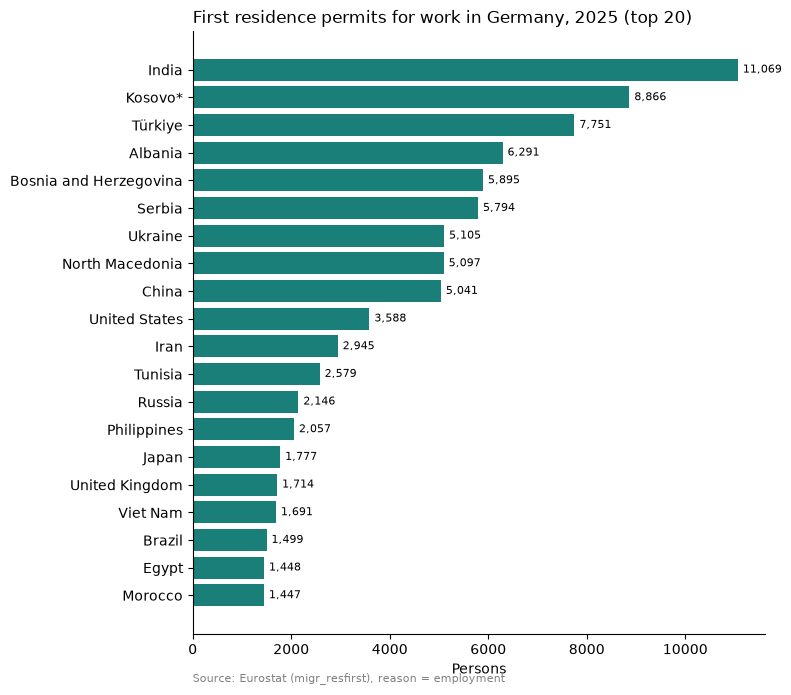

In [4]:
fig, ax = plt.subplots(figsize=(8, 7))
plot_data = top20[2025].sort_values()
ax.barh(plot_data.index, plot_data.values, color="#1B7F79")

ax.set_title("First residence permits for work in Germany, 2025 (top 20)", loc="left", fontsize=12)
ax.set_xlabel("Persons")
ax.spines[["top", "right"]].set_visible(False)
for y, value in enumerate(plot_data.values):
    ax.text(value + 100, y, f"{value:,.0f}", va="center", fontsize=8)
ax.text(0, -0.08, "Source: Eurostat (migr_resfirst), reason = employment", transform=ax.transAxes, fontsize=8, color="grey")

plt.tight_layout()
fig.savefig(FIGURES / "01_top20_permits_2025.png", dpi=200)
plt.show()

> **Finding 1 — a surprise.** The ranking is different from the original plan. India and the **Western Balkans** (Kosovo, Albania, Bosnia and Herzegovina, Serbia, North Macedonia) lead. The **Philippines** is only #14 and **Indonesia** is not in the top 20.
>
> **Why?** Work permits cover **all jobs** (IT, engineering, construction…), not only care. And many care workers may not enter with a work permit at all.

### Side note: the 2024 drop

Many countries fall in 2024 and rise again in 2025 (e.g. India: 12,289 → 8,358 → 11,069).

In [5]:
dip_2024 = (top20[2024] < top20[2023]) & (top20[2024] < top20[2025])
print(f"{dip_2024.sum()} of {len(top20)} countries have a dip in 2024.")
top20.loc[dip_2024, [2023, 2024, 2025]]

14 of 20 countries have a dip in 2024.


year,2023,2024,2025
country,,,
India,"12,289","8,358","11,069"
Kosovo*,"7,662","5,122","8,866"
Türkiye,"6,424","5,686","7,751"
Albania,"5,485","3,939","6,291"
Bosnia and Herzegovina,"6,753","4,065","5,895"
Serbia,"6,484","3,638","5,794"
North Macedonia,"4,188","3,279","5,097"
China,"4,300","3,712","5,041"
United States,"3,918","3,023","3,588"


**Interpretation (to confirm):** when almost all countries drop together, the cause is probably on the **German side** (data reporting or processing), not in the origin countries. This matters for **RQ2**: a 2024 gap between searches and permits may come from the permit data, not from Google Trends.

---
## 4. Step 2 — Do care workers come through education?

In Germany, many people become care workers through **vocational training (Ausbildung)**. Eurostat may count these permits as **education**, not work. So we download the same data with reason = Education (`EDUC`).

In [6]:
URL_EDUC = URL.replace("c[reason]=EMP", "c[reason]=EDUC")

raw_educ = load_eurostat(URL_EDUC, RAW / "eurostat_migr_resfirst_DE_EDUC_2023_2025.csv")
educ = clean_permits(raw_educ)

compare = pd.DataFrame({"work_2025": emp[2025], "education_2025": educ[2025]})
compare["total_2025"] = compare["work_2025"] + compare["education_2025"]
compare["share_education_%"] = compare["education_2025"] / compare["total_2025"] * 100

# Countries from the original plan
plan = ["India", "Philippines", "Indonesia", "Viet Nam", "Türkiye", "Brazil"]
(compare.loc[plan]
    .style
    .format("{:,.0f}", subset=["work_2025", "education_2025", "total_2025"])
    .format("{:.1f}%", subset=["share_education_%"]))

Loaded saved snapshot: eurostat_migr_resfirst_DE_EDUC_2023_2025.csv


,work_2025,education_2025,total_2025,share_education_%
country,,,,
India,"11,069","23,889","34,958",68.3%
Philippines,"2,057",742,"2,799",26.5%
Indonesia,"1,139","1,819","2,958",61.5%
Viet Nam,"1,691","8,390","10,081",83.2%
Türkiye,"7,751","6,713","14,464",46.4%
Brazil,"1,499","1,535","3,034",50.6%


> **Finding 2 — work permits hide care countries.** **Viet Nam** has only 1,691 work permits, but **8,390 education permits (83%)**. With education included, Viet Nam becomes one of the largest countries. Indonesia (61%) also comes mostly through education. The **Philippines** is the opposite (27%): Filipino nurses are usually already trained and come for work.
>
> **But:** "education" mixes **university students** and **vocational trainees**. We need to split them.

---
## 5. Step 3 — University or vocational training?

The Eurostat table `migr_resedu` splits education permits into:
- **Study** (`EDUC_STU`): university and college
- **Other educational reasons** (`EDUC_OTH`): everything else, **including vocational training (Ausbildung)**

In [7]:
URL_EDU = (URL
           .replace("migr_resfirst", "migr_resedu")
           .replace("c[reason]=EMP", "c[reason]=EDUC_STU,EDUC_OTH"))

raw_edu = load_eurostat(URL_EDU, RAW / "eurostat_migr_resedu_DE_2023_2025.csv")

edu = raw_edu[(raw_edu["TIME_PERIOD"] == 2025) & (~raw_edu["citizen"].isin(GROUPS))]
edu = edu.pivot_table(index="citizen", columns="reason", values="OBS_VALUE")
edu = edu.rename(columns={"Other educational reasons": "other_education", "Study": "study"})
edu["share_other_%"] = edu["other_education"] / (edu["other_education"] + edu["study"]) * 100

(edu.loc[plan]
    .style
    .format("{:,.0f}", subset=["other_education", "study"])
    .format("{:.1f}%", subset=["share_other_%"]))

Loaded saved snapshot: eurostat_migr_resedu_DE_2023_2025.csv


reason,other_education,study,share_other_%
citizen,,,
India,"4,791","19,098",20.1%
Philippines,552,190,74.4%
Indonesia,"1,090",729,59.9%
Viet Nam,"7,010","1,380",83.6%
Türkiye,"1,388","5,325",20.7%
Brazil,291,"1,244",19.0%


In [8]:
# Which countries send the most people for "other education" (incl. Ausbildung)?
edu.sort_values("other_education", ascending=False).head(10)[["other_education", "study"]]

reason,other_education,study
citizen,,
Viet Nam,"7,010","1,380"
India,"4,791","19,098"
Morocco,"4,122","1,517"
Cameroon,"1,920","1,144"
Tunisia,"1,440","1,379"
Syria,"1,389",674
Türkiye,"1,388","5,325"
Iran,"1,307","4,051"
Ukraine,"1,176",535


> **Finding 3 — two different education stories.**
> - **Viet Nam:** 7,010 "other education" vs. 1,380 study → mostly **vocational training**, a strong care-training country.
> - **India:** 19,098 of 23,889 education permits (80%) are **university study** → India's care link comes from work permits, not training.
> - **New countries appear:** **Morocco** (#3, 4,122) and **Cameroon** (#4, 1,920) send many people for "other education". They were not in the original plan.

---
## 6. Step 4 — Care-specific evidence (Federal Employment Agency)

Eurostat permits have **no job information**. To confirm the link to **care work**, we use the Federal Employment Agency (BA) report on care occupations.

**Source:** Bundesagentur für Arbeit (2026): *Arbeitsmarktsituation in Pflegeberufen*, Blickpunkt Arbeitsmarkt, May 2026, pp. 6, 10–11; BA press release No. 16, 8 May 2026. Data: employees subject to social insurance, June 2025. Care occupations = KldB 2010 codes 813 (nursing) and 821 (elderly care).

| Group | Countries | Foreign care workers 2025 | Since 2015 |
|---|---|---|---|
| EU | — | ~100,000 | doubled |
| Western Balkans | Albania, Bosnia and Herzegovina, Kosovo, North Macedonia, Montenegro, Serbia | 55,000 | about 5× |
| **Triple Win partners** | **Philippines, Tunisia, Indonesia, India** | **43,000** | from 2,000 |
| Asylum countries ("Asyl 8") | Afghanistan, Eritrea, Iraq, Iran, Nigeria, Pakistan, Somalia, Syria | ~33,000 | from <2,000 |
| Ukraine | — | 15,000 | from ~5,000 |

- In total, **353,000 care workers (20%)** in Germany have a foreign nationality.
- The three largest non-EU nationalities in care are **Bosnia and Herzegovina, Türkiye and India**.
- **Triple Win** is the German government's programme to recruit nurses from its partner countries.

> **Finding 4.** The Triple Win countries and the BA top 3 are **confirmed care countries**. Refugee groups (Asyl 8, Ukraine) are large, but they did **not migrate through job search**, so Google job searches do not fit them.

---
## 7. Step 5 — Putting the evidence together (triangulation)

Each source alone is weak: permits have no job information, and the BA report has no full country list. So we combine them. **A country is selected if it has at least 2 of these 3 types of evidence:**

| Evidence | Rule | Source |
|---|---|---|
| **E1 – Flow** | Top 20 in care-route permits (work + other education), 2025 | Eurostat |
| **E2 – Training** | Top 10 in "other education" permits (incl. Ausbildung), 2025 | Eurostat |
| **E3 – Care** | Triple Win partner country or BA top-3 care nationality | BA |

**and it is not excluded** for one of these reasons:

| Exclusion | Countries | Why |
|---|---|---|
| Refugee route | Ukraine, Syria, Iran (Asyl 8) | Migration not driven by job search |
| Google is not the main search engine | China, Russia | Google Trends not representative |
| High-income, not care migration | United States, Japan, United Kingdom | Different type of migration; the UK is also a comparison destination |

In [9]:
TRIPLE_WIN = ["Philippines", "Tunisia", "Indonesia", "India"]
BA_TOP3_CARE = ["Bosnia and Herzegovina", "Türkiye", "India"]
EXCLUDED = {
    "Ukraine": "refugee route (war)",
    "Syria": "refugee route (Asyl 8)",
    "Iran": "refugee route (Asyl 8); Google access limited",
    "China": "Google not the main search engine",
    "Russia": "Google not the main search engine",
    "United States": "high-income, not care migration",
    "Japan": "high-income, not care migration",
    "United Kingdom": "high-income; comparison destination",
}

evidence = pd.DataFrame({
    "work_2025": emp[2025],
    "other_education_2025": edu["other_education"],
}).fillna(0)
evidence["care_route_2025"] = evidence["work_2025"] + evidence["other_education_2025"]

evidence["E1_flow"] = evidence["care_route_2025"].rank(ascending=False) <= 20
evidence["E2_training"] = evidence["other_education_2025"].rank(ascending=False) <= 10
evidence["E3_care"] = evidence.index.isin(TRIPLE_WIN + BA_TOP3_CARE)
evidence["n_evidence"] = evidence[["E1_flow", "E2_training", "E3_care"]].sum(axis=1)
evidence["excluded_because"] = evidence.index.map(EXCLUDED).fillna("")
evidence["selected"] = (evidence["n_evidence"] >= 2) & (evidence["excluded_because"] == "")

# Show every country with at least one type of evidence
candidates = evidence[evidence["n_evidence"] >= 1].sort_values(["selected", "n_evidence", "care_route_2025"], ascending=False)
candidates

,work_2025,other_education_2025,care_route_2025,E1_flow,E2_training,E3_care,n_evidence,excluded_because,selected
India,"11,069","4,791","15,860",True,True,True,3,,True
Türkiye,"7,751","1,388","9,139",True,True,True,3,,True
Tunisia,"2,579","1,440","4,019",True,True,True,3,,True
Indonesia,"1,139","1,090","2,229",True,True,True,3,,True
Viet Nam,"1,691","7,010","8,701",True,True,False,2,,True
Bosnia and Herzegovina,"5,895",127,"6,022",True,False,True,2,,True
Morocco,"1,447","4,122","5,569",True,True,False,2,,True
Philippines,"2,057",552,"2,609",True,False,True,2,,True
Cameroon,382,"1,920","2,302",True,True,False,2,,True
Ukraine,"5,105","1,176","6,281",True,True,False,2,refugee route (war),False


In [10]:
selected = candidates[candidates["selected"]]
print(f"Selected: {len(selected)} countries")
print(", ".join(selected.index))

Selected: 9 countries
India, Türkiye, Tunisia, Indonesia, Viet Nam, Bosnia and Herzegovina, Morocco, Philippines, Cameroon


### Notes on the decisions

- **Western Balkans:** Kosovo, Albania, Serbia and North Macedonia have large work permit numbers (E1), but only one type of evidence. They use a special work rule (*Westbalkanregelung*, since 2016), which could hide the effect of the 2023–2024 reforms. **Bosnia and Herzegovina** is kept as the Western Balkans example, because it is the largest non-EU nationality in German care work.
- **Morocco and Cameroon** were not in the original plan. They are selected because the data shows a strong training route (E1 + E2).
- **Brazil** was in the original plan but has no strong evidence (care route #22, mostly university study), so it is not selected.

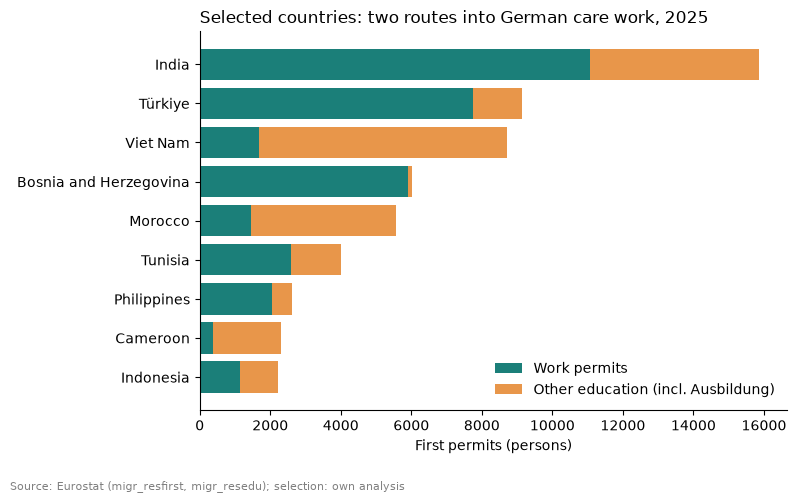

In [11]:
# Sort so the largest country is at the top
plot_data = selected.sort_values("care_route_2025")[["work_2025", "other_education_2025"]]

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(plot_data.index, plot_data["work_2025"], color="#1B7F79", label="Work permits")
ax.barh(plot_data.index, plot_data["other_education_2025"], left=plot_data["work_2025"],
        color="#E8964A", label="Other education (incl. Ausbildung)")

ax.set_title("Selected countries: two routes into German care work, 2025", loc="left", fontsize=12)
ax.set_xlabel("First permits (persons)")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
fig.subplots_adjust(bottom=0.17)
fig.text(0.01, 0.01, "Source: Eurostat (migr_resfirst, migr_resedu); selection: own analysis", fontsize=8, color="grey")
fig.savefig(FIGURES / "01_selected_countries_routes_2025.png", dpi=200)
plt.show()

> **Finding 5 — two routes.** The chart shows why both permit types matter: **India, Türkiye, Bosnia and Herzegovina and the Philippines** come mainly through **work**; **Viet Nam, Morocco and Cameroon** come mainly through **training**. Tunisia and Indonesia use both.

---
## 8. Step 6 — Rule 4: does Google Trends have enough data?

A country is only useful if Google Trends shows **real values, not mostly zeros**. As a first check, we use the broad **topic "Germany" (Country in Europe)**, which counts searches about Germany **in all languages** (e.g. *Đức*, *Almanya*, *Alemania*).

**Settings for all Google Trends data in this project**

| Setting | Value | Why |
|---|---|---|
| Search | Topic "Germany – Country in Europe" | Works across languages |
| Location | Each selected country (whole country, not a city) | Matches the Eurostat data |
| Period | **1 Jan 2015 – 31 Oct 2026** | Last **complete** month; the same period for every download |
| Category / type | All categories · Web Search | Default |

> **Note:** All Google Trends data: Jan 2015 – Oct 2026 (last complete month). Downloaded manually from trends.google.com on 13 Nov 2026. The download time appears in Google's original file names; the files themselves contain no period information.

**Pass rule:** at most 10% of months are zero.

In [12]:
GT_CHECK = RAW / "gt_check"

# ISO 2-letter codes (file names) -> Eurostat country names
CODES = {
    "IN": "India", "TR": "Türkiye", "VN": "Viet Nam", "MA": "Morocco", "TN": "Tunisia",
    "PH": "Philippines", "ID": "Indonesia", "BA": "Bosnia and Herzegovina", "CM": "Cameroon",
}

series = {}
for code_, country in CODES.items():
    gt = pd.read_csv(GT_CHECK / f"{code_}_topic_germany.csv", parse_dates=["Time"], index_col="Time")
    series[country] = gt.iloc[:, 0].replace("<1", 0.5).astype(float)   # "<1" = very small value
gt_germany = pd.DataFrame(series)

rule4 = pd.DataFrame({
    "months": gt_germany.count(),
    "first_month": gt_germany.apply(lambda s: s.first_valid_index().strftime("%Y-%m")),
    "last_month": gt_germany.apply(lambda s: s.last_valid_index().strftime("%Y-%m")),
    "zero_months": (gt_germany == 0).sum(),
    "min": gt_germany.min(),
    "median": gt_germany.median(),
})
rule4["zero_share_%"] = rule4["zero_months"] / rule4["months"] * 100
rule4["rule4_pass"] = rule4["zero_share_%"] <= 10
rule4

,months,first_month,last_month,zero_months,min,median,zero_share_%,rule4_pass
India,142,2015-01,2026-10,0,12,23,0,True
Türkiye,142,2015-01,2026-10,0,24,46,0,True
Viet Nam,142,2015-01,2026-10,0,12,24,0,True
Morocco,142,2015-01,2026-10,0,22,38,0,True
Tunisia,142,2015-01,2026-10,0,20,37,0,True
Philippines,142,2015-01,2026-10,0,18,34,0,True
Indonesia,142,2015-01,2026-10,0,17,35,0,True
Bosnia and Herzegovina,142,2015-01,2026-10,0,40,55,0,True
Cameroon,142,2015-01,2026-10,0,32,52,0,True


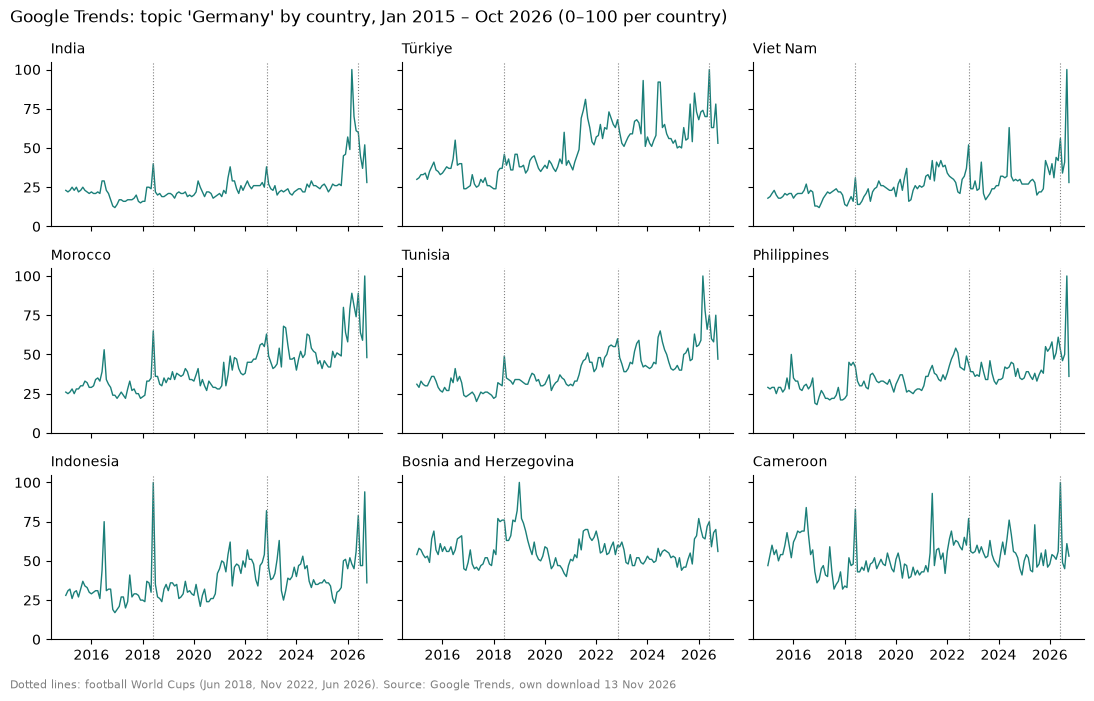

In [13]:
fig, axes = plt.subplots(3, 3, figsize=(11, 7), sharex=True, sharey=True)
world_cups = pd.to_datetime(["2018-06-01", "2022-11-01", "2026-06-01"])

for ax, country in zip(axes.flat, gt_germany.columns):
    ax.plot(gt_germany.index, gt_germany[country], color="#1B7F79", linewidth=1)
    for date in world_cups:
        ax.axvline(date, color="grey", linestyle=":", linewidth=0.8)
    ax.set_title(country, fontsize=10, loc="left")
    ax.set_ylim(0, 105)
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle("Google Trends: topic 'Germany' by country, Jan 2015 – Oct 2026 (0–100 per country)", x=0.01, ha="left", fontsize=12)
plt.tight_layout()
fig.subplots_adjust(bottom=0.08)
fig.text(0.01, 0.01, "Dotted lines: football World Cups (Jun 2018, Nov 2022, Jun 2026). Source: Google Trends, own download 13 Nov 2026",
         fontsize=8, color="grey")
fig.savefig(FIGURES / "01_rule4_gt_topic_germany.png", dpi=200)
plt.show()

> **Finding 6 — all 9 countries pass Rule 4.** Every series has 142 months (Jan 2015 – Oct 2026) and **no zero months**.
>
> **Two cautions:**
> - This is the **easy test**. The topic "Germany" is broad. With **specific** keywords (e.g. "nurse Germany"), smaller countries such as Bosnia and Herzegovina or Cameroon may still show zeros. Rule 4 is checked again in Notebook 03.
> - The topic includes a lot of **noise**: several countries peak in **World Cup** months (football), and many peak in **September 2026** (cause unknown). The top and rising related queries confirm this (e.g. in Viet Nam mostly football results). This is why Notebook 02 looks for **work-, care- and training-related keywords**.
>
> *Each value is 0–100 **within its own country**, so the levels cannot be compared between countries yet. Making them comparable is RQ1 (Notebook 04, `gtab`).*

In [14]:
# Add the Rule 4 result to the selection table
# (drop first, so the cell can be run again without an error)
selected = selected.drop(columns=["zero_share_%", "rule4_pass"], errors="ignore").join(rule4[["zero_share_%", "rule4_pass"]])
selected[["care_route_2025", "n_evidence", "zero_share_%", "rule4_pass"]]

,care_route_2025,n_evidence,zero_share_%,rule4_pass
India,"15,860",3,0,True
Türkiye,"9,139",3,0,True
Tunisia,"4,019",3,0,True
Indonesia,"2,229",3,0,True
Viet Nam,"8,701",2,0,True
Bosnia and Herzegovina,"6,022",2,0,True
Morocco,"5,569",2,0,True
Philippines,"2,609",2,0,True
Cameroon,"2,302",2,0,True


---
## 9. Save results

In [15]:
emp.to_csv(PROCESSED / "permits_DE_employment_2023_2025.csv")
edu.to_csv(PROCESSED / "permits_DE_education_split_2025.csv")
evidence.to_csv(PROCESSED / "country_evidence_2025.csv")
selected.to_csv(PROCESSED / "country_selection.csv")
rule4.to_csv(PROCESSED / "rule4_gt_check.csv")
print("Saved to", PROCESSED.resolve())

Saved to C:\Users\Tayami\Downloads\F26_MDSSB-CAP-01_Capstone Project\data\processed


---
## 10. Summary

**Story in five steps**
1. **Work permits** gave a first ranking, but it covers all jobs and missed key care countries.
2. **Education permits** showed that Viet Nam and Indonesia come mostly through education.
3. **Splitting education** showed this is mostly **vocational training** (Viet Nam, Morocco, Cameroon), while India's education permits are mostly **university study**.
4. **BA care statistics** confirmed the Triple Win countries and the top care nationalities (Bosnia and Herzegovina, Türkiye, India).
5. **Triangulation** of the three sources selected **9 countries**.
6. **Rule 4:** all 9 countries have enough Google Trends data for the topic "Germany" (no zero months).

**Selected countries:** India, Türkiye, Viet Nam, Morocco, Tunisia, Philippines, Indonesia, Bosnia and Herzegovina, Cameroon.

**Limitations**
- Permit data has no job information; "other education" also includes language courses and school exchanges.
- The BA report gives groups, not a full country list.
- 2024 permit numbers look unusually low for most countries (to check in Eurostat metadata).
- Western Balkans countries (except Bosnia and Herzegovina) are not included because of their special work rule.

**Next steps**
- **Rule 4 (second check):** repeat with the specific keywords in Notebook 03.
- Optional: nursing recognitions by country of training (Destatis) as a fourth source.
- **Notebook 02:** find search keywords for each selected country, starting from the related queries already saved in `data/raw/gt_check/`, plus social media.